# Predicción del nivel de riesgo cardiometabólico en un conjunto de datos sintético de salud mediante técnicas de clasificación supervisada

**Proyecto de aula · Minería de Datos · Tercer corte: revisión, optimización y despliegue del modelo en Streamlit**

**Integrantes:** Iván David Pertuz · Diego Llanos
**Profesor:** José Escorcia-Gutierrez
**Universidad de la Costa (CUC)** · Departamento de Ciencias de la Computación y Electrónica

> El notebook se ejecuta de principio a fin con la semilla `SEMILLA = 42`. Las secciones 1 a 5 corresponden al segundo avance y se conservan sin cambios. La **sección 6** es nueva (tercer corte): revisa el rendimiento, optimiza el modelo, compara antes y después y exporta el pipeline que usa la aplicación de Streamlit.

## 0. Continuidad con el primer avance

| Elemento | Definición |
|---|---|
| **Tipo de proyecto** | Clasificación supervisada multiclase |
| **Pregunta de investigación** | ¿Es posible clasificar el nivel de riesgo (Bajo, Medio, Alto) de una persona a partir de sus indicadores clínicos y de estilo de vida, y cuáles de esas características se asocian más con la clasificación? |
| **Dataset** | *Dataset Sintético de Salud para EDA* (`Dataset_Sintetico_Salud_EDA.xlsx`) |
| **Descripción** | 500 registros sintéticos de personas (enero–diciembre de 2025) con 14 variables: edad, género, IMC, glucosa, presión sistólica, colesterol, actividad física, consumo de tabaco, horas de sueño, nivel de estrés, consultas médicas y nivel de riesgo. |
| **Fuente y descarga** | Proporcionado por el docente en el aula virtual (Moodle) de la asignatura Minería de Datos, CUC. Datos generados sintéticamente con semilla fija; no corresponden a pacientes reales (hoja `Ficha_tecnica`). |
| **Variable objetivo** | `Nivel_Riesgo` (categórica ordinal: Bajo, Medio, Alto) |

**Cambios frente al primer avance y su justificación**

1. **Se excluye `Mes_Registro` de los predictores.** En el EDA del primer avance la proporción mensual de riesgo Alto osciló sin tendencia clara (entre ≈14 % y ≈42 %) con solo 31–51 registros por mes, y no se sigue a las mismas personas en el tiempo. Usar el mes podría introducir patrones espurios de la simulación.
2. **Se pasa del diagnóstico a una versión final de los datos.** En el primer avance se diagnosticaron nulos, duplicados y outliers sin modificar el archivo. Aquí se toman decisiones explícitas: se retiran los 3 duplicados exactos, los nulos se imputan dentro del pipeline y los valores extremos se conservan (sección 1.3).
3. **Se añaden el modelado y la evaluación** (regresión logística, árbol de decisión y random forest), que corresponden a este segundo corte.

# 1. Preparación del entorno y de los datos

Librerías utilizadas: pandas, NumPy, Matplotlib, seaborn y scikit-learn. Si faltan, ejecute una vez `%pip install pandas numpy matplotlib seaborn openpyxl scikit-learn`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# numpy 2.x con Apple Accelerate emite RuntimeWarning espurios en productos matriciales
# (no afectan los resultados); se silencian para mantener legible el notebook.
warnings.filterwarnings("ignore", category=RuntimeWarning)

SEMILLA = 42                      # semilla única para que todo el notebook sea reproducible
ORDEN_RIESGO = ["Bajo", "Medio", "Alto"]
COLORES_RIESGO = {"Bajo": "#59A14F", "Medio": "#EDC948", "Alto": "#E15759"}

# Carpeta donde se guardan las figuras que se usan en el informe
CARPETA_FIG = Path("figuras")
CARPETA_FIG.mkdir(exist_ok=True)


def guardar(nombre):
    """Guarda la figura actual en la carpeta de figuras del informe."""
    plt.savefig(CARPETA_FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")


## 1.1 Carga del dataset y diccionario de variables

In [2]:
ruta_datos = Path("Dataset_Sintetico_Salud_EDA.xlsx")
if not ruta_datos.exists():
    raise FileNotFoundError("Ubique Dataset_Sintetico_Salud_EDA.xlsx en la misma carpeta del notebook.")

df_original = pd.read_excel(ruta_datos, sheet_name="Datos")
diccionario = pd.read_excel(ruta_datos, sheet_name="Diccionario")

print(f"Dimensiones originales: {df_original.shape[0]} filas y {df_original.shape[1]} columnas")
df_original.head()


Dimensiones originales: 500 filas y 14 columnas


,ID_Paciente,Mes_Registro,Edad,Genero,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Actividad_Fisica,Fumador,Horas_Sueno,Nivel_Estres,Consultas_Medicas,Nivel_Riesgo
0,PAC-0001,2025-08-01,33,Masculino,21.6,70.0,110,149.0,Alta,No,6.5,6,0,Bajo
1,PAC-0002,2025-03-01,56,Femenino,33.8,129.0,130,171.0,Baja,No,6.8,5,0,Alto
2,PAC-0003,2025-03-01,57,Masculino,25.0,95.0,129,208.0,Moderada,Sí,5.8,8,6,Medio
3,PAC-0004,2025-11-01,68,Masculino,28.2,95.0,125,253.0,Moderada,No,7.3,6,5,Medio
4,PAC-0005,2025-02-01,47,Masculino,28.5,111.0,129,192.0,Alta,Sí,6.8,7,0,Medio


In [3]:
diccionario

,Variable,Tipo,Unidad / valores,Descripción
0,ID_Paciente,Identificador,Texto,Código sintético del paciente. No contiene inf...
1,Mes_Registro,Temporal,Mes de 2025,Mes en que se registró la observación.
2,Edad,Numérica discreta,Años,Edad de la persona al momento del registro.
3,Genero,Categórica nominal,"Femenino, Masculino, Otro/No reporta",Categoría de género simulada.
4,IMC,Numérica continua,kg/m²,Índice de masa corporal simulado.
5,Glucosa_mg_dL,Numérica continua,mg/dL,Medición simulada de glucosa.
6,Presion_Sistolica_mmHg,Numérica continua,mmHg,Medición simulada de presión arterial sistólica.
7,Colesterol_mg_dL,Numérica continua,mg/dL,Medición simulada de colesterol total.
8,Actividad_Fisica,Categórica ordinal,"Baja, Moderada, Alta",Nivel general de actividad física simulado.
9,Fumador,Categórica binaria,"Sí, No",Indica consumo de tabaco en el escenario simul...


**Interpretación.** Cada fila es el registro de una persona en un mes de 2025. El diccionario confirma que `Nivel_Riesgo` es una *variable objetivo didáctica construida a partir de varias características*. Por eso se esperan asociaciones fuertes con las variables clínicas, y los resultados deben leerse como la capacidad de los modelos para recuperar esa regla, no como evidencia clínica.

## 1.2 Revisión de calidad: tipos, nulos, duplicados y categorías

In [4]:
resumen_calidad = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "nulos": df_original.isna().sum(),
    "porcentaje_nulos": (df_original.isna().mean() * 100).round(2),
    "valores_unicos": df_original.nunique(dropna=True),
})

print(f"Duplicados exactos: {df_original.duplicated().sum()}")
print(f"ID_Paciente repetidos: {df_original['ID_Paciente'].duplicated().sum()}")
resumen_calidad


Duplicados exactos: 3
ID_Paciente repetidos: 3


,tipo,nulos,porcentaje_nulos,valores_unicos
ID_Paciente,str,0,0.0,497
Mes_Registro,datetime64[us],0,0.0,12
Edad,int64,0,0.0,65
Genero,str,0,0.0,3
IMC,float64,5,1.0,168
Glucosa_mg_dL,float64,6,1.2,82
Presion_Sistolica_mmHg,int64,0,0.0,66
Colesterol_mg_dL,float64,3,0.6,124
Actividad_Fisica,str,4,0.8,3
Fumador,str,0,0.0,2


In [5]:
# Revisión de categorías: buscamos espacios, mayúsculas o escrituras distintas de una misma categoría
for columna in ["Genero", "Actividad_Fisica", "Fumador", "Nivel_Riesgo"]:
    valores = df_original[columna].value_counts(dropna=False)
    print(f"{columna}: {dict(valores)}")


Genero: {'Femenino': np.int64(264), 'Masculino': np.int64(224), 'Otro/No reporta': np.int64(12)}
Actividad_Fisica: {'Moderada': np.int64(214), 'Baja': np.int64(174), 'Alta': np.int64(108), nan: np.int64(4)}
Fumador: {'No': np.int64(388), 'Sí': np.int64(112)}
Nivel_Riesgo: {'Medio': np.int64(196), 'Bajo': np.int64(170), 'Alto': np.int64(134)}


**Interpretación.**
- **Duplicados:** hay 3 filas duplicadas exactas, que coinciden con 3 `ID_Paciente` repetidos (la ficha técnica indica que son intencionales). Se eliminarán **antes** de dividir los datos para que una misma observación no quede en entrenamiento y prueba a la vez (fuga de información).
- **Nulos:** son pocos (entre 0.6 % y 1.4 %) y están en `IMC` (5), `Glucosa_mg_dL` (6), `Colesterol_mg_dL` (3), `Horas_Sueno` (7) y `Actividad_Fisica` (4). No se eliminan filas: se imputan con la **mediana** (numéricas) o la **moda** (categóricas) dentro del pipeline, de modo que los valores de imputación se calculan solo con el conjunto de entrenamiento.
- **Tipos y categorías:** los tipos son coherentes con el diccionario. Las categorías no presentan escrituras inconsistentes. `Genero = Otro/No reporta` tiene solo 12 registros, lo que limita cualquier conclusión sobre ese grupo.

## 1.3 Valores atípicos

In [6]:
variables_numericas = [
    "Edad", "IMC", "Glucosa_mg_dL", "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL", "Horas_Sueno", "Nivel_Estres", "Consultas_Medicas",
]

df_original[variables_numericas].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
Edad,500.0,47.62,15.18,18.0,37.00,47.0,58.0,85.0
IMC,495.0,27.21,4.80,17.0,24.05,26.8,30.2,58.2
Glucosa_mg_dL,494.0,104.71,24.55,62.0,93.00,103.0,114.0,336.0
Presion_Sistolica_mmHg,500.0,123.33,14.70,85.0,114.00,122.0,132.0,226.0
Colesterol_mg_dL,497.0,189.16,29.83,115.0,166.00,190.0,212.0,266.0
Horas_Sueno,493.0,7.00,0.96,3.8,6.40,7.1,7.6,9.8
Nivel_Estres,500.0,5.57,2.02,1.0,4.00,5.0,7.0,10.0
Consultas_Medicas,500.0,2.64,1.70,0.0,1.00,3.0,4.0,9.0


In [7]:
def resumen_outliers_iqr(dataframe, columnas):
    filas = []
    for columna in columnas:
        serie = dataframe[columna].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        filas.append({
            "variable": columna,
            "limite_inferior": round(lim_inf, 2),
            "limite_superior": round(lim_sup, 2),
            "posibles_outliers": int(((serie < lim_inf) | (serie > lim_sup)).sum()),
            "minimo": serie.min(),
            "maximo": serie.max(),
        })
    return pd.DataFrame(filas).sort_values("posibles_outliers", ascending=False)


tabla_outliers = resumen_outliers_iqr(df_original, variables_numericas)
tabla_outliers


,variable,limite_inferior,limite_superior,posibles_outliers,minimo,maximo
5,Horas_Sueno,4.60,9.40,9,3.8,9.8
2,Glucosa_mg_dL,61.50,145.50,7,62.0,336.0
3,Presion_Sistolica_mmHg,87.00,159.00,6,85.0,226.0
1,IMC,14.83,39.42,4,17.0,58.2
7,Consultas_Medicas,-3.50,8.50,1,0.0,9.0
0,Edad,5.50,89.50,0,18.0,85.0
4,Colesterol_mg_dL,97.00,281.00,0,115.0,266.0
6,Nivel_Estres,-0.50,11.50,0,1.0,10.0


In [8]:
# Casos más extremos de glucosa y presión: revisamos si son fisiológicamente posibles
df_original.nlargest(5, "Glucosa_mg_dL")[
    ["ID_Paciente", "Edad", "IMC", "Glucosa_mg_dL", "Presion_Sistolica_mmHg", "Nivel_Riesgo"]
]


,ID_Paciente,Edad,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Nivel_Riesgo
411,PAC-0412,39,24.1,336.0,108,Alto
121,PAC-0122,69,24.4,318.0,131,Alto
24,PAC-0025,50,18.0,292.0,126,Alto
305,PAC-0306,43,26.6,281.0,117,Alto
276,PAC-0277,75,31.9,158.0,147,Alto


In [9]:
df_original.nlargest(5, "Presion_Sistolica_mmHg")[
    ["ID_Paciente", "Edad", "Glucosa_mg_dL", "Presion_Sistolica_mmHg", "Colesterol_mg_dL", "Nivel_Riesgo"]
]


,ID_Paciente,Edad,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Nivel_Riesgo
230,PAC-0231,18,76.0,226,209.0,Alto
90,PAC-0091,43,101.0,214,143.0,Alto
444,PAC-0445,73,110.0,208,147.0,Alto
74,PAC-0075,61,102.0,160,157.0,Medio
296,PAC-0297,85,136.0,156,196.0,Alto


**Decisión sobre los atípicos.** La regla IQR marca 9 posibles atípicos en `Horas_Sueno`, 7 en glucosa, 6 en presión sistólica, 4 en IMC y 1 en consultas. Los más llamativos son una glucosa de 336 mg/dL y una presión de 226 mmHg. Estos valores son poco frecuentes, pero **fisiológicamente posibles**, y todos los registros con glucosa > 280 mg/dL o presión > 200 mmHg están etiquetados como riesgo **Alto**. Es decir, son coherentes con la etiqueta y no parecen errores de captura. **Se conservan.** Eliminarlos quitaría justo los casos que el modelo debe reconocer como de alto riesgo. Para limitar su influencia se usa la mediana en la imputación y se compara un modelo lineal con modelos basados en árboles, que son poco sensibles a la escala de los extremos.

## 1.4 Variables excluidas, fugas de información y versión final de los datos

- `ID_Paciente`: identificador administrativo sin significado predictivo (un valor por persona). Usarlo permitiría memorizar códigos.
- `Mes_Registro`: excluida por la razón explicada en la sección 0.
- **Fuga de información:** `Nivel_Riesgo` no se usa en ningún paso de preparación. Imputación, escalamiento y codificación se ajustan dentro de un `Pipeline`, solo con los datos de entrenamiento.
- **Transformaciones:** imputación (mediana/moda), estandarización (`StandardScaler`) de las numéricas, necesaria para la regresión logística regularizada, y *one-hot encoding* de `Genero`, `Actividad_Fisica` y `Fumador`.

In [10]:
# Versión final de los datos para EDA y modelado
df = df_original.drop_duplicates().copy()

variables_categoricas = ["Genero", "Actividad_Fisica", "Fumador"]
variables_predictoras = variables_numericas + variables_categoricas
objetivo = "Nivel_Riesgo"
excluidas = ["ID_Paciente", "Mes_Registro"]

df["Nivel_Riesgo"] = pd.Categorical(df["Nivel_Riesgo"], categories=ORDEN_RIESGO, ordered=True)

print(f"Registros: {len(df_original)} -> {len(df)} (se retiraron {len(df_original) - len(df)} duplicados exactos)")
print(f"Variables: {df_original.shape[1]} en total -> {len(variables_predictoras)} predictoras + 1 objetivo")
print("Excluidas:", excluidas)
print("Nulos que se imputarán dentro del pipeline:")
print(df[variables_predictoras].isna().sum()[lambda s: s > 0])


Registros: 500 -> 497 (se retiraron 3 duplicados exactos)
Variables: 14 en total -> 11 predictoras + 1 objetivo
Excluidas: ['ID_Paciente', 'Mes_Registro']
Nulos que se imputarán dentro del pipeline:
IMC                 5
Glucosa_mg_dL       6
Colesterol_mg_dL    3
Horas_Sueno         7
Actividad_Fisica    4
dtype: int64


# 2. Análisis exploratorio orientado a la pregunta

## 2.1 Distribución de la variable objetivo

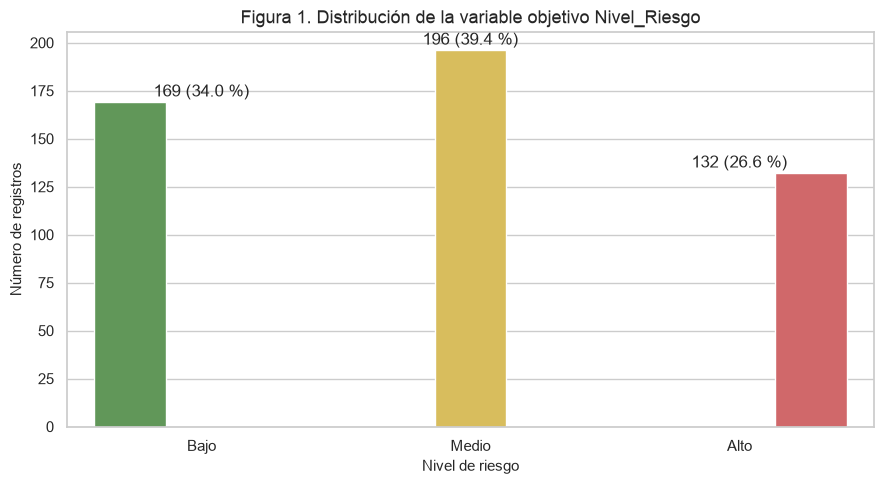

Razón clase mayoritaria / minoritaria: 1.48


,registros,porcentaje
Nivel_Riesgo,,
Bajo,169,34.0
Medio,196,39.4
Alto,132,26.6


In [11]:
conteo = df[objetivo].value_counts().reindex(ORDEN_RIESGO)
porcentaje = (conteo / conteo.sum() * 100).round(1)

ax = sns.countplot(data=df, x=objetivo, order=ORDEN_RIESGO, hue=objetivo,
                   palette=COLORES_RIESGO, legend=False)
for i, (n, p) in enumerate(zip(conteo, porcentaje)):
    ax.text(i, n + 3, f"{n} ({p} %)", ha="center")
ax.set(title="Figura 1. Distribución de la variable objetivo Nivel_Riesgo",
       xlabel="Nivel de riesgo", ylabel="Número de registros")
plt.tight_layout()
guardar("fig1_objetivo")
plt.show()

print("Razón clase mayoritaria / minoritaria:", round(conteo.max() / conteo.min(), 2))
pd.DataFrame({"registros": conteo, "porcentaje": porcentaje})


**Interpretación (Figura 1).** Tras retirar duplicados, la clase **Medio** es la más frecuente (196; 39.4 %), seguida de **Bajo** (169; 34.0 %) y **Alto** (132; 26.6 %). La razón entre la clase mayoritaria y la minoritaria es de 1.48, un **desbalance leve**. Aun así, para evitar que los modelos favorezcan a la clase Medio: (a) la división entrenamiento/prueba será **estratificada**, (b) se usa `class_weight="balanced"` y (c) la comparación se apoya en métricas *macro*, no solo en el accuracy.

## 2.2 Distribución de las variables numéricas

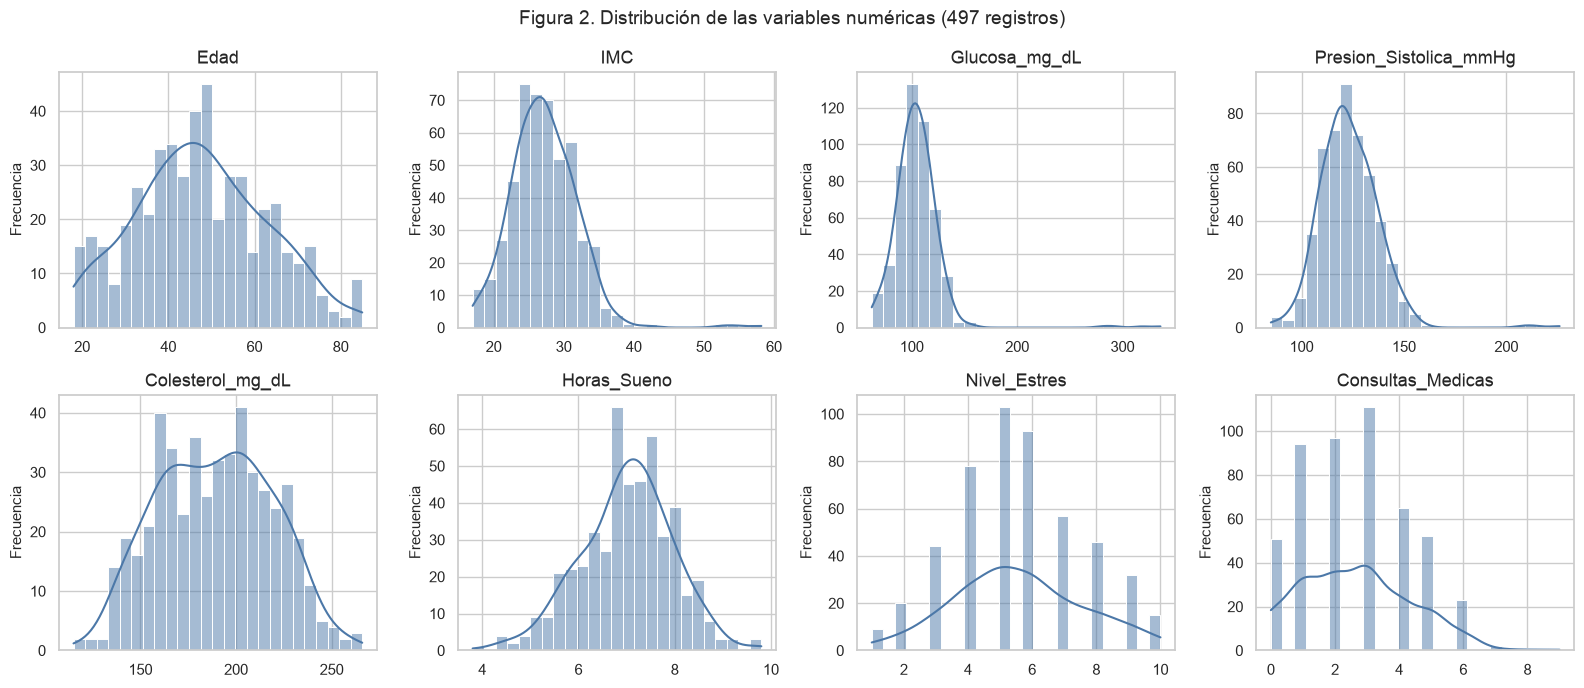

,media,mediana,desv_est,asimetria
Edad,47.59,47.00,15.18,0.18
IMC,27.22,26.85,4.80,1.25
Glucosa_mg_dL,104.74,103.00,24.61,4.60
Presion_Sistolica_mmHg,123.28,122.00,14.69,1.53
Colesterol_mg_dL,189.03,189.50,29.81,0.03
Horas_Sueno,7.00,7.10,0.96,-0.21
Nivel_Estres,5.58,5.00,2.03,0.14
Consultas_Medicas,2.64,3.00,1.70,0.39


In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, columna in zip(axes.ravel(), variables_numericas):
    sns.histplot(data=df, x=columna, kde=True, bins=25, ax=ax, color="#4C78A8")
    ax.set(title=columna, xlabel="", ylabel="Frecuencia")
fig.suptitle("Figura 2. Distribución de las variables numéricas (497 registros)", fontsize=14)
plt.tight_layout()
guardar("fig2_distribuciones")
plt.show()

forma = pd.DataFrame({
    "media": df[variables_numericas].mean(),
    "mediana": df[variables_numericas].median(),
    "desv_est": df[variables_numericas].std(),
    "asimetria": df[variables_numericas].skew(),
}).round(2)
forma


**Interpretación (Figura 2).** `Edad`, `Colesterol_mg_dL`, `Horas_Sueno` y `Nivel_Estres` son aproximadamente simétricas (asimetría entre −0.21 y 0.18), y su media y mediana casi coinciden. `Glucosa_mg_dL` (asimetría 4.60), `Presion_Sistolica_mmHg` (1.53) e `IMC` (1.25) tienen **cola derecha** por los valores extremos de la sección 1.3. Por eso la mediana describe mejor su centro y la estandarización de esas variables queda influida por los extremos. Esto se tendrá en cuenta al leer los coeficientes del modelo lineal.

## 2.3 Comparación de las variables según el nivel de riesgo

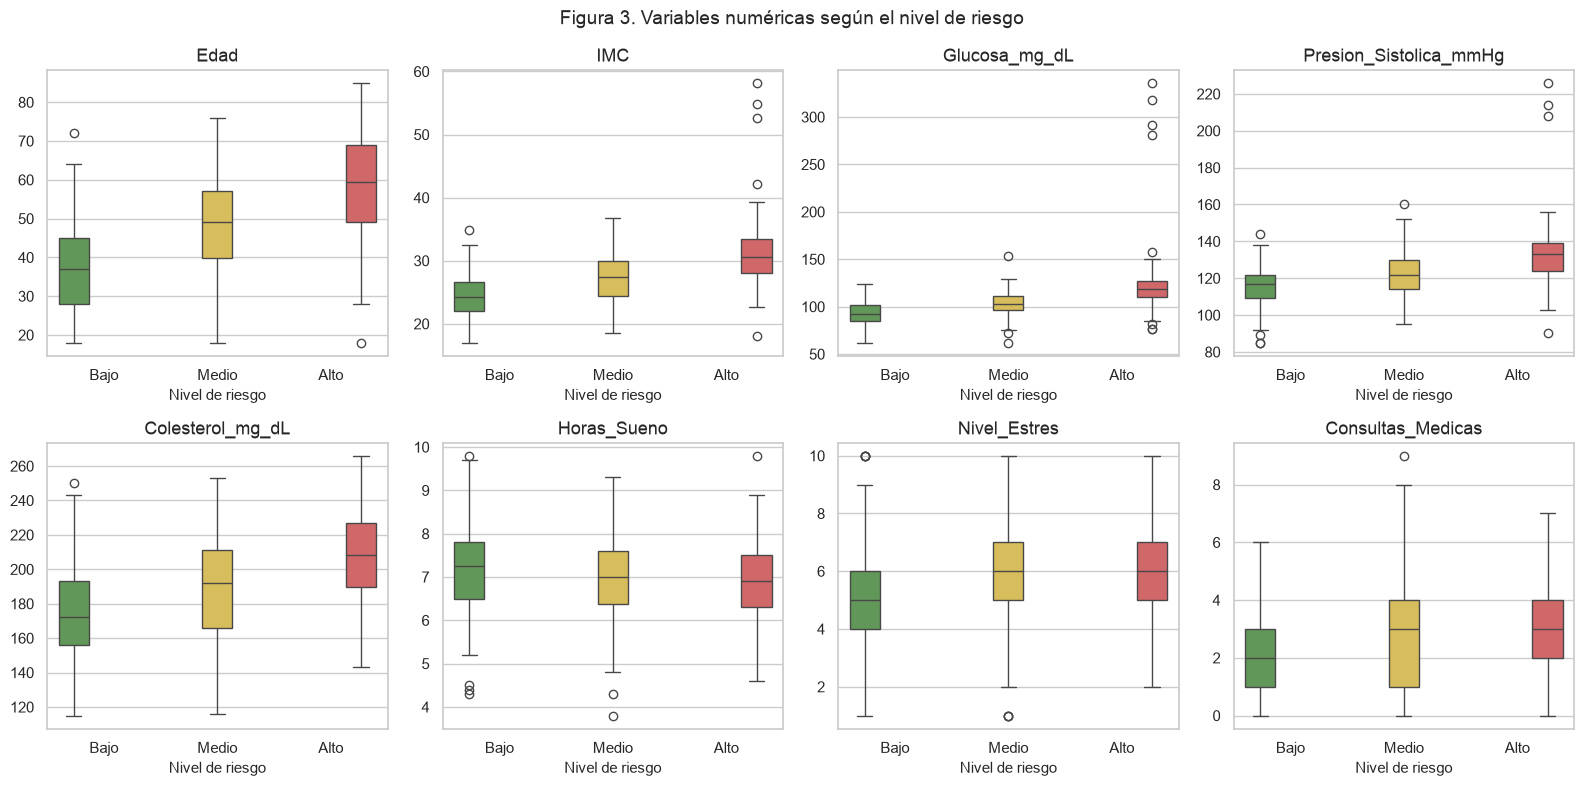

,Edad,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Horas_Sueno,Nivel_Estres,Consultas_Medicas
Nivel_Riesgo,,,,,,,,
Bajo,37.0,24.3,92.0,117.0,172.0,7.2,5.0,2.0
Medio,49.0,27.4,103.0,122.0,192.0,7.0,6.0,3.0
Alto,59.5,30.6,119.0,133.0,208.5,6.9,6.0,3.0


In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, columna in zip(axes.ravel(), variables_numericas):
    sns.boxplot(data=df, x=objetivo, y=columna, order=ORDEN_RIESGO, hue=objetivo,
                palette=COLORES_RIESGO, legend=False, ax=ax)
    ax.set(title=columna, xlabel="Nivel de riesgo", ylabel="")
fig.suptitle("Figura 3. Variables numéricas según el nivel de riesgo", fontsize=14)
plt.tight_layout()
guardar("fig3_boxplots_riesgo")
plt.show()

medianas_por_clase = df.groupby(objetivo, observed=True)[variables_numericas].median().round(1)
medianas_por_clase


**Interpretación (Figura 3).** Las medianas de **edad** (37 → 49 → 59.5 años), **IMC** (24.3 → 27.4 → 30.6), **glucosa** (92 → 103 → 119 mg/dL), **presión sistólica** (117 → 122 → 133 mmHg) y **colesterol** (172 → 192 → 208.5 mg/dL) aumentan de forma ordenada de Bajo a Alto. En cambio, `Horas_Sueno` (7.2 → 6.9 h) y `Nivel_Estres` (5 → 6) cambian muy poco. En todas las variables las cajas de clases vecinas **se solapan**: ninguna variable por sí sola separa las tres clases, lo que justifica usar modelos multivariados.

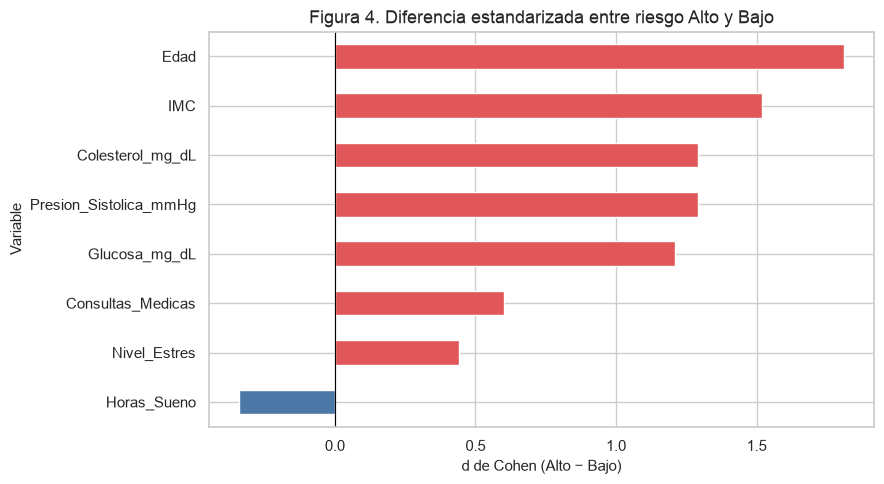

Edad                      1.81
IMC                       1.52
Colesterol_mg_dL          1.29
Presion_Sistolica_mmHg    1.29
Glucosa_mg_dL             1.21
Consultas_Medicas         0.60
Nivel_Estres              0.44
Horas_Sueno              -0.34
dtype: float64

In [14]:
# Tamaño de la diferencia entre Alto y Bajo en desviaciones estándar (d de Cohen aproximado).
# Sirve para ordenar qué variables separan mejor las clases antes de modelar.
def d_cohen(a, b):
    a, b = a.dropna(), b.dropna()
    sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sd


separacion = pd.Series({
    c: d_cohen(df.loc[df[objetivo] == "Alto", c], df.loc[df[objetivo] == "Bajo", c])
    for c in variables_numericas
}).sort_values(key=abs, ascending=False).round(2)

ax = separacion.plot(kind="barh", color=["#E15759" if v > 0 else "#4C78A8" for v in separacion])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Figura 4. Diferencia estandarizada entre riesgo Alto y Bajo",
       xlabel="d de Cohen (Alto − Bajo)", ylabel="Variable")
plt.tight_layout()
guardar("fig4_separacion")
plt.show()
separacion


**Interpretación (Figura 4).** Para ordenar las variables por capacidad de separación se calculó la diferencia estandarizada entre Alto y Bajo. Las mayores diferencias son las de **edad (1.81 DE)**, **IMC (1.52)**, **colesterol y presión (1.29)** y **glucosa (1.21)**. La de glucosa queda algo reducida porque sus extremos inflan la desviación estándar. Consultas médicas (0.60), estrés (0.44) y sueño (−0.34) muestran diferencias pequeñas. Se trata de **asociaciones** en datos sintéticos, no de efectos causales.

## 2.4 Variables categóricas frente al nivel de riesgo

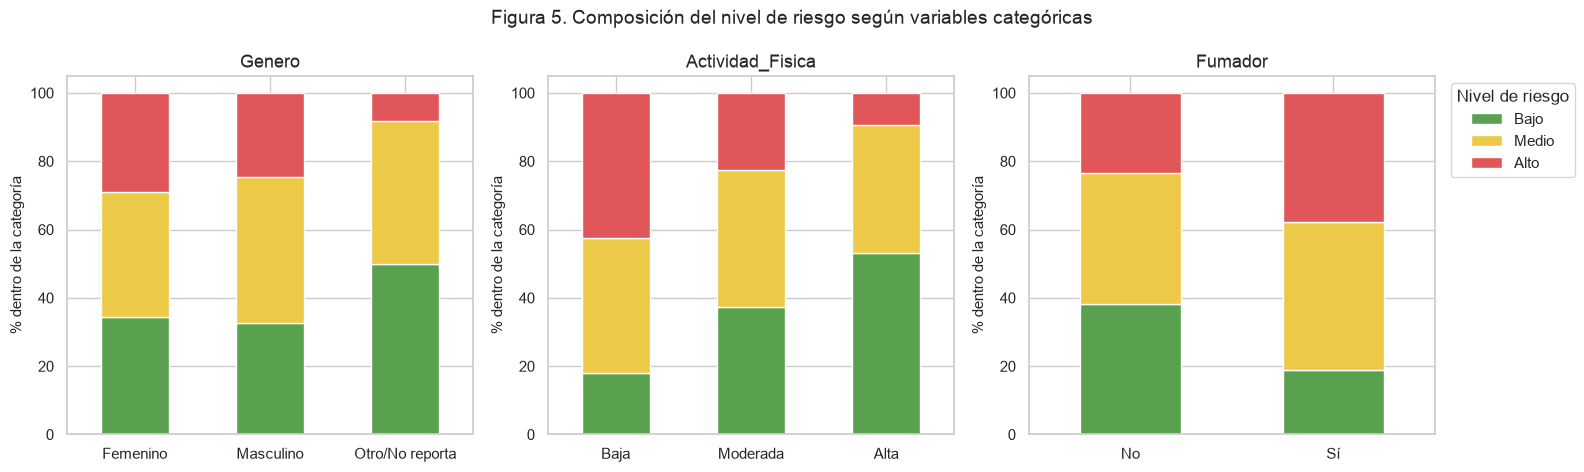


Genero (% por fila)
Nivel_Riesgo     Bajo  Medio  Alto
Genero                            
Femenino         34.4   36.6  29.0
Masculino        32.7   42.6  24.7
Otro/No reporta  50.0   41.7   8.3

Actividad_Fisica (% por fila)
Nivel_Riesgo      Bajo  Medio  Alto
Actividad_Fisica                   
Baja              18.0   39.5  42.4
Moderada          37.4   40.2  22.4
Alta              53.3   37.4   9.3

Fumador (% por fila)
Nivel_Riesgo  Bajo  Medio  Alto
Fumador                        
No            38.3   38.3  23.3
Sí            18.9   43.2  37.8


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ordenes = {"Genero": None, "Actividad_Fisica": ["Baja", "Moderada", "Alta"], "Fumador": ["No", "Sí"]}
tablas_cat = {}
for ax, columna in zip(axes, variables_categoricas):
    tabla = pd.crosstab(df[columna], df[objetivo], normalize="index") * 100
    if ordenes[columna]:
        tabla = tabla.reindex(ordenes[columna])
    tablas_cat[columna] = tabla.round(1)
    tabla.plot(kind="bar", stacked=True, ax=ax, legend=False,
               color=[COLORES_RIESGO[c] for c in ORDEN_RIESGO])
    ax.set(title=columna, xlabel="", ylabel="% dentro de la categoría")
    ax.tick_params(axis="x", rotation=0)
axes[-1].legend(title="Nivel de riesgo", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Figura 5. Composición del nivel de riesgo según variables categóricas", fontsize=14)
plt.tight_layout()
guardar("fig5_categoricas")
plt.show()

for columna, tabla in tablas_cat.items():
    print(f"\n{columna} (% por fila)")
    print(tabla)


**Interpretación (Figura 5).** Se usan porcentajes por fila porque los grupos tienen tamaños distintos.
- **Actividad física:** la proporción de riesgo Alto baja de **42.4 %** (actividad baja) a 22.4 % (moderada) y a **9.3 %** (alta), y la de riesgo Bajo sube de 18.0 % a 53.3 %. Es la variable categórica más asociada al riesgo.
- **Fumador:** entre fumadores el riesgo Alto es de 37.8 %, frente a 23.3 % en no fumadores.
- **Género:** Femenino y Masculino tienen composiciones parecidas. El grupo `Otro/No reporta` (n = 12) es demasiado pequeño para interpretarlo.

## 2.5 Relaciones entre variables numéricas

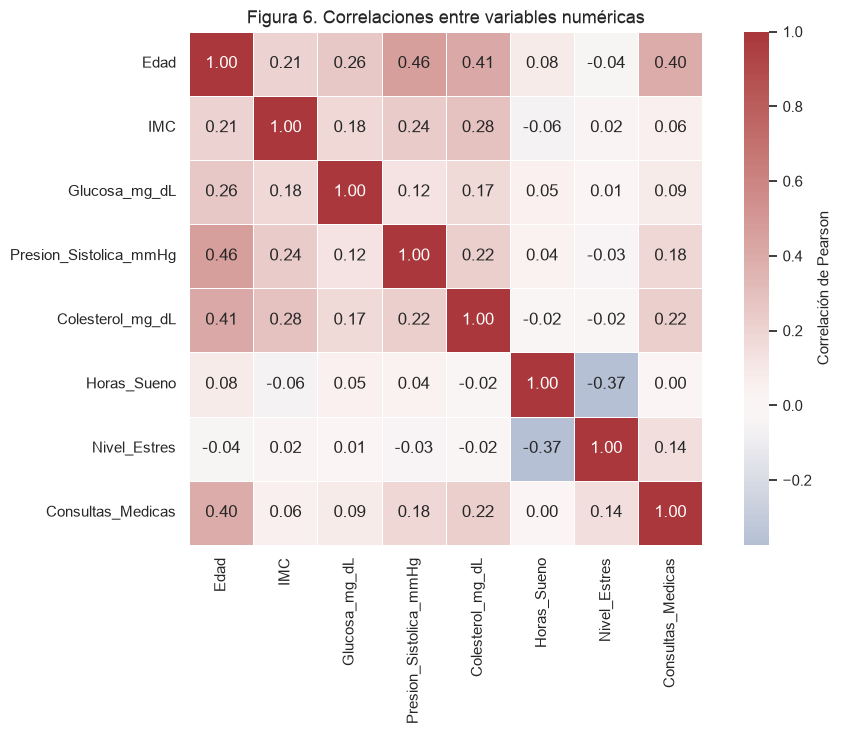

Edad         Presion_Sistolica_mmHg    0.465
             Colesterol_mg_dL          0.405
             Consultas_Medicas         0.398
Horas_Sueno  Nivel_Estres             -0.373
IMC          Colesterol_mg_dL          0.284
Edad         Glucosa_mg_dL             0.258
dtype: float64

In [16]:
matriz_corr = df[variables_numericas].corr()

plt.figure(figsize=(10, 7.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True,
            linewidths=0.5, cbar_kws={"label": "Correlación de Pearson"})
plt.title("Figura 6. Correlaciones entre variables numéricas")
plt.tight_layout()
guardar("fig6_correlaciones")
plt.show()

pares = (
    matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool))
    .stack().sort_values(key=abs, ascending=False)
)
pares.head(6).round(3)


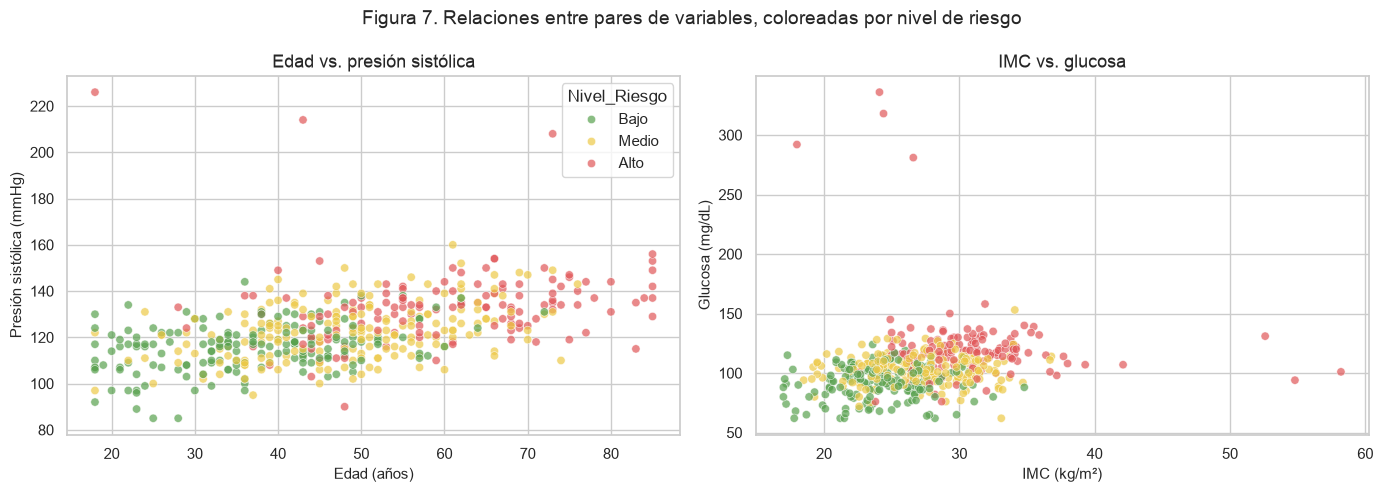

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="Edad", y="Presion_Sistolica_mmHg", hue=objetivo, hue_order=ORDEN_RIESGO,
                palette=COLORES_RIESGO, alpha=0.7, ax=axes[0])
axes[0].set(title="Edad vs. presión sistólica", xlabel="Edad (años)", ylabel="Presión sistólica (mmHg)")
sns.scatterplot(data=df, x="IMC", y="Glucosa_mg_dL", hue=objetivo, hue_order=ORDEN_RIESGO,
                palette=COLORES_RIESGO, alpha=0.7, ax=axes[1], legend=False)
axes[1].set(title="IMC vs. glucosa", xlabel="IMC (kg/m²)", ylabel="Glucosa (mg/dL)")
fig.suptitle("Figura 7. Relaciones entre pares de variables, coloreadas por nivel de riesgo", fontsize=14)
plt.tight_layout()
guardar("fig7_dispersion")
plt.show()


**Interpretación (Figuras 6 y 7).** Las correlaciones son a lo sumo **moderadas**: edad–presión (0.465), edad–colesterol (0.405), edad–consultas (0.398) y sueño–estrés (−0.373). Ningún par supera 0.5, así que no hay **multicolinealidad fuerte** que obligue a eliminar variables. En los diagramas de dispersión, los puntos de riesgo Alto se concentran en edades, presiones, IMC y glucosas mayores, pero con una zona central de mezcla amplia. Esto anticipa que los errores de clasificación se darán sobre todo entre clases vecinas.

**Decisiones de modelado derivadas del EDA:** (1) se conservan las 11 variables predictoras, porque incluso las de menor asociación (sueño, estrés) podrían aportar en combinación y no hay redundancia fuerte; (2) se usa estratificación y pesos balanceados por el desbalance leve; (3) se compara un modelo lineal con modelos de árboles por la presencia de extremos y posibles interacciones.

# 3. Selección y entrenamiento de modelos

**Modelos seleccionados y justificación**

| Modelo | Por qué es pertinente |
|---|---|
| **Regresión logística multinomial** | Modelo base interpretable. Sus coeficientes indican la dirección de la asociación de cada variable con cada clase. El EDA mostró diferencias monótonas entre clases, lo que favorece un modelo lineal. |
| **Árbol de decisión** (`max_depth=5`, `min_samples_leaf=8`) | Produce reglas "si… entonces" fáciles de explicar y captura interacciones no lineales. La profundidad se limita para reducir el sobreajuste. |
| **Random forest** (300 árboles, `min_samples_leaf=3`) | Combina muchos árboles entrenados sobre muestras bootstrap y subconjuntos aleatorios de variables (Breiman, 2001). Reduce la varianza de un árbol individual y es robusto a valores extremos. |

No se realiza búsqueda de hiperparámetros en esta entrega; se usan valores razonables y fijos.

## 3.1 Separación de predictoras y objetivo, y división entrenamiento/prueba (75/25 estratificada)

In [18]:
X = df[variables_predictoras]
y = df[objetivo].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=y
)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
pd.DataFrame({
    "entrenamiento_%": y_train.value_counts(normalize=True).reindex(ORDEN_RIESGO).mul(100).round(1),
    "prueba_%": y_test.value_counts(normalize=True).reindex(ORDEN_RIESGO).mul(100).round(1),
})


Entrenamiento: (372, 11) | Prueba: (125, 11)


,entrenamiento_%,prueba_%
Nivel_Riesgo,,
Bajo,33.9,34.4
Medio,39.5,39.2
Alto,26.6,26.4


**Interpretación.** Se usan 372 registros para entrenar y 125 para probar. La estratificación conserva casi idénticas las proporciones de clase (Alto: 26.6 % frente a 26.4 %), así que la prueba es representativa.

## 3.2 Preparación de variables y definición de los pipelines

In [19]:
def crear_preprocesador():
    """Imputación + escalamiento para numéricas; imputación + one-hot para categóricas.
    Al estar dentro de un Pipeline, todo se ajusta SOLO con los datos de entrenamiento."""
    numerico = Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalamiento", StandardScaler()),
    ])
    categorico = Pipeline([
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numerico, variables_numericas),
        ("cat", categorico, variables_categoricas),
    ])


modelos = {
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=5, min_samples_leaf=8,
                                                class_weight="balanced", random_state=SEMILLA),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced", random_state=SEMILLA),
}

pipelines = {nombre: Pipeline([("prep", crear_preprocesador()), ("modelo", m)]) for nombre, m in modelos.items()}


## 3.3 Entrenamiento y predicción sobre el conjunto de prueba

In [20]:
def metricas(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_Alto": recall_score(y_real, y_pred, labels=["Alto"], average="macro", zero_division=0),
    }


predicciones, filas = {}, []
for nombre, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    predicciones[nombre] = pipe.predict(X_test)
    fila = {"Modelo": nombre, **metricas(y_test, predicciones[nombre])}
    fila["Accuracy_train"] = accuracy_score(y_train, pipe.predict(X_train))
    filas.append(fila)

tabla_metricas = pd.DataFrame(filas).set_index("Modelo")
tabla_metricas["Brecha_train_test"] = tabla_metricas["Accuracy_train"] - tabla_metricas["Accuracy"]
tabla_metricas.round(3)


,Accuracy,Precision_macro,Recall_macro,F1_macro,Recall_Alto,Accuracy_train,Brecha_train_test
Modelo,,,,,,,
Regresión logística,0.856,0.854,0.858,0.856,0.848,0.871,0.015
Árbol de decisión,0.648,0.676,0.646,0.656,0.606,0.809,0.161
Random forest,0.832,0.849,0.837,0.838,0.909,0.978,0.146


# 4. Evaluación e interpretación

## 4.1 Resultados por clase

In [21]:
reportes = {}
for nombre, pred in predicciones.items():
    reportes[nombre] = pd.DataFrame(
        classification_report(y_test, pred, labels=ORDEN_RIESGO, output_dict=True, zero_division=0)
    ).T.loc[ORDEN_RIESGO, ["precision", "recall", "f1-score", "support"]]

por_clase = pd.concat(reportes, names=["Modelo", "Clase"]).round(3)
por_clase


precision  recall  f1-score  support
Modelo              Clase                                      
Regresión logística Bajo       0.909   0.930     0.920     43.0
                    Medio      0.830   0.796     0.812     49.0
                    Alto       0.824   0.848     0.836     33.0
Árbol de decisión   Bajo       0.674   0.721     0.697     43.0
                    Medio      0.556   0.612     0.583     49.0
                    Alto       0.800   0.606     0.690     33.0
Random forest       Bajo       0.941   0.744     0.831     43.0
                    Medio      0.750   0.857     0.800     49.0
                    Alto       0.857   0.909     0.882     33.0

## 4.2 Matrices de confusión

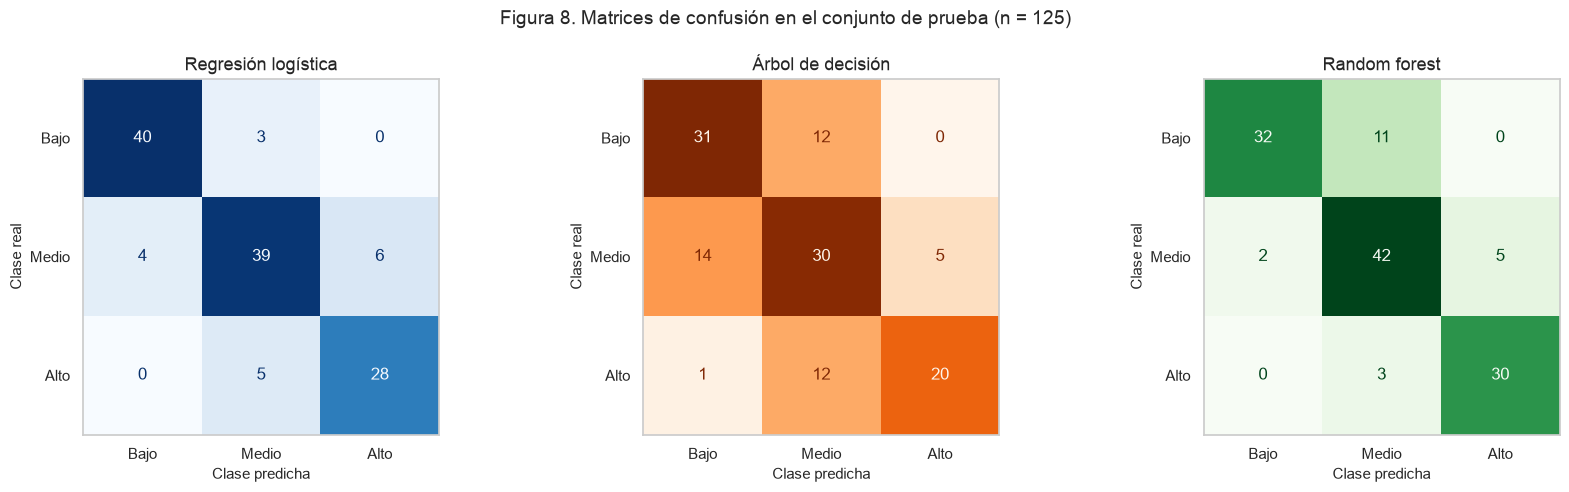


Regresión logística
            Pred Bajo  Pred Medio  Pred Alto
Real Bajo          40           3          0
Real Medio          4          39          6
Real Alto           0           5         28

Árbol de decisión
            Pred Bajo  Pred Medio  Pred Alto
Real Bajo          31          12          0
Real Medio         14          30          5
Real Alto           1          12         20

Random forest
            Pred Bajo  Pred Medio  Pred Alto
Real Bajo          32          11          0
Real Medio          2          42          5
Real Alto           0           3         30


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
matrices = {}
for ax, (nombre, pred), cmap in zip(axes, predicciones.items(), ["Blues", "Oranges", "Greens"]):
    matrices[nombre] = confusion_matrix(y_test, pred, labels=ORDEN_RIESGO)
    ConfusionMatrixDisplay(matrices[nombre], display_labels=ORDEN_RIESGO).plot(
        ax=ax, cmap=cmap, values_format="d", colorbar=False)
    ax.set(title=nombre, xlabel="Clase predicha", ylabel="Clase real")
    ax.grid(False)
fig.suptitle("Figura 8. Matrices de confusión en el conjunto de prueba (n = 125)", fontsize=14)
plt.tight_layout()
guardar("fig8_matrices")
plt.show()

for nombre, m in matrices.items():
    print(f"\n{nombre}")
    print(pd.DataFrame(m, index=[f"Real {c}" for c in ORDEN_RIESGO], columns=[f"Pred {c}" for c in ORDEN_RIESGO]))


In [23]:
# Clasificamos los errores por gravedad: un "escalón" (clases vecinas) o dos escalones (Bajo <-> Alto).
# El error más costoso para el problema es un paciente Alto clasificado como Bajo o Medio (riesgo no detectado).
rango = {c: i for i, c in enumerate(ORDEN_RIESGO)}
filas = []
for nombre, m in matrices.items():
    i_b, i_m, i_a = rango["Bajo"], rango["Medio"], rango["Alto"]
    filas.append({
        "Modelo": nombre,
        "Aciertos": int(np.trace(m)),
        "Errores_un_escalon": int(m[i_b, i_m] + m[i_m, i_b] + m[i_m, i_a] + m[i_a, i_m]),
        "Errores_Bajo_Alto": int(m[i_b, i_a] + m[i_a, i_b]),
        "Alto_no_detectados": int(m[i_a, i_b] + m[i_a, i_m]),
        "Falsas_alarmas_Alto": int(m[i_b, i_a] + m[i_m, i_a]),
    })
tabla_errores = pd.DataFrame(filas).set_index("Modelo")
tabla_errores


,Aciertos,Errores_un_escalon,Errores_Bajo_Alto,Alto_no_detectados,Falsas_alarmas_Alto
Modelo,,,,,
Regresión logística,107,18,0,5,6
Árbol de decisión,81,43,1,13,5
Random forest,104,21,0,3,5


**Interpretación (Figura 8).** Filas = clase real; columnas = clase predicha.
- **Regresión logística:** 107/125 aciertos. Sus 18 errores son todos entre **clases vecinas** y no confunde nunca Bajo con Alto. De los 33 pacientes Alto detecta 28 (recall 0.848); los 5 restantes los clasifica como Medio. Genera 6 falsas alarmas Medio → Alto.
- **Random forest:** 103/125 aciertos y tampoco comete errores Bajo↔Alto. Tiene el mismo recall de Alto (28/33) y menos falsas alarmas (4). Su debilidad es la clase **Bajo**: clasifica a 12 de 43 pacientes Bajo como Medio (recall de Bajo 0.721).
- **Árbol de decisión:** 81/125 aciertos. Acumula 43 errores entre clases vecinas, solo detecta 20 de 33 pacientes Alto (recall 0.606) y comete **un error grave Alto → Bajo**.

**¿Qué error importa más?** En un problema de tamizaje de riesgo, el error más costoso es un paciente **Alto no detectado**, que podría quedar sin seguimiento. Le sigue una confusión de dos escalones (Bajo ↔ Alto). Una falsa alarma (Medio → Alto) tiene un costo menor. Con ese criterio, la logística y el random forest empatan en pacientes Alto no detectados (5) y ninguno comete errores de dos escalones.

## 4.3 Validación cruzada estratificada (5 particiones)

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, pipe in pipelines.items():
    res = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
    filas.append({
        "Modelo": nombre,
        "Accuracy_CV": res["test_accuracy"].mean(),
        "F1_macro_CV": res["test_f1_macro"].mean(),
        "F1_macro_CV_desv": res["test_f1_macro"].std(),
        "F1_macro_train_CV": res["train_f1_macro"].mean(),
    })
tabla_cv = pd.DataFrame(filas).set_index("Modelo")
tabla_cv.round(3)


,Accuracy_CV,F1_macro_CV,F1_macro_CV_desv,F1_macro_train_CV
Modelo,,,,
Regresión logística,0.841,0.844,0.030,0.880
Árbol de decisión,0.618,0.627,0.015,0.784
Random forest,0.775,0.780,0.014,0.980


**Qué aporta este análisis.** Una sola división de 125 registros puede ser favorable o desfavorable por azar. La validación cruzada estratificada de 5 particiones evalúa cada modelo sobre los 497 registros y además mide la **estabilidad** (desviación estándar) y la **brecha** entre entrenamiento y validación:
- **Regresión logística:** F1-macro de 0.844 ± 0.030, muy cerca del de prueba (0.856), con una brecha pequeña (0.880 en entrenamiento). **No hay sobreajuste.**
- **Random forest:** F1-macro de 0.784 ± 0.021. Su resultado en prueba (0.829) fue algo optimista frente a la validación cruzada. Además, el F1 de entrenamiento es casi perfecto (0.985), una señal clara de **sobreajuste**: memoriza el entrenamiento.
- **Árbol de decisión:** F1-macro de 0.627 ± 0.015, el más bajo, con una brecha de ≈ 0.16 entre entrenamiento y validación.

## 4.4 Comparación de los modelos

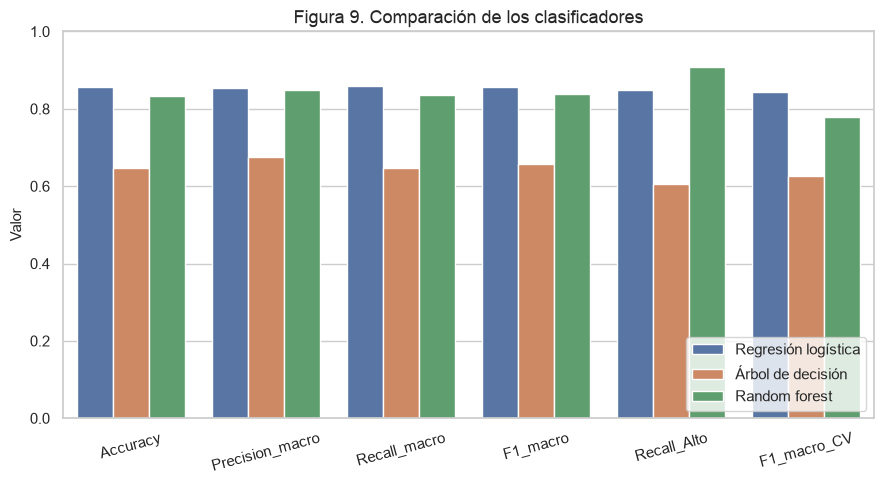

,Accuracy,Precision_macro,Recall_macro,F1_macro,Recall_Alto,F1_macro_CV
Modelo,,,,,,
Regresión logística,0.856,0.854,0.858,0.856,0.848,0.844
Árbol de decisión,0.648,0.676,0.646,0.656,0.606,0.627
Random forest,0.832,0.849,0.837,0.838,0.909,0.780


In [25]:
comparacion = tabla_metricas[["Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "Recall_Alto"]].copy()
comparacion["F1_macro_CV"] = tabla_cv["F1_macro_CV"]

larga = comparacion.reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
ax = sns.barplot(data=larga, x="Métrica", y="Valor", hue="Modelo")
ax.set(title="Figura 9. Comparación de los clasificadores", xlabel="", ylabel="Valor", ylim=(0, 1))
ax.legend(loc="lower right")
plt.xticks(rotation=15)
plt.tight_layout()
guardar("fig9_comparacion")
plt.show()
comparacion.round(3)


**Selección del modelo (Figura 9).** No se elige solo por el accuracy. Se consideran cinco evidencias:
1. **Métricas macro en prueba:** la logística obtiene el mejor F1-macro (0.856) y recall macro (0.858), seguida del random forest (0.829 / 0.822) y del árbol (0.656 / 0.646).
2. **Validación cruzada:** confirma el orden con mayor margen (0.844 frente a 0.784 y 0.627).
3. **Error más costoso:** la logística y el random forest empatan en recall de Alto (0.848) y ninguno confunde Bajo con Alto; el árbol sí.
4. **Generalización:** la brecha entrenamiento–prueba de la logística es de 0.015, frente a 0.160 del random forest y 0.161 del árbol.
5. **Interpretabilidad:** la logística ofrece coeficientes con dirección clara (sección 4.5); el random forest es menos transparente.

**Modelo seleccionado: regresión logística multinomial.** El random forest queda como alternativa competitiva, con menos falsas alarmas de Alto, pero con sobreajuste y peor desempeño medio en validación cruzada.

## 4.5 Interpretación de los modelos

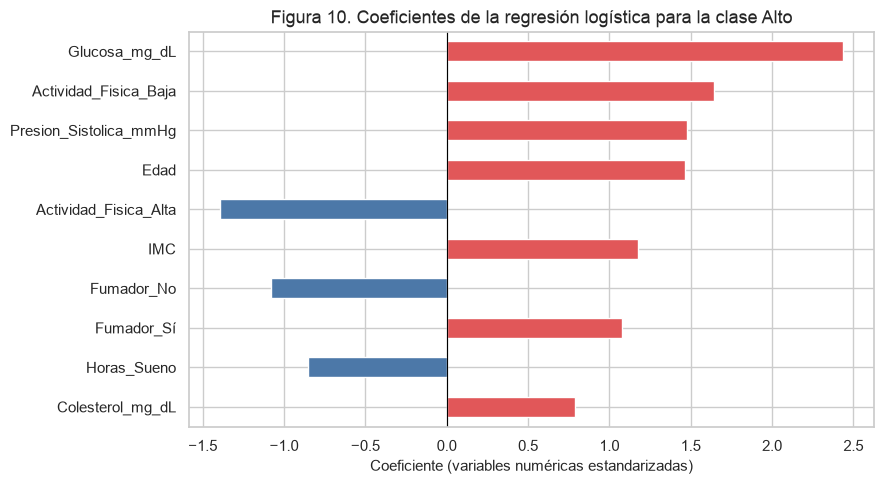

Glucosa_mg_dL                2.435
Actividad_Fisica_Baja        1.644
Presion_Sistolica_mmHg       1.479
Edad                         1.464
Actividad_Fisica_Alta       -1.392
IMC                          1.174
Fumador_No                  -1.083
Fumador_Sí                   1.078
Horas_Sueno                 -0.855
Colesterol_mg_dL             0.789
Genero_Otro/No reporta      -0.671
Nivel_Estres                 0.522
Genero_Femenino              0.424
Actividad_Fisica_Moderada   -0.257
Genero_Masculino             0.242
Consultas_Medicas            0.099
dtype: float64

In [26]:
# Interpretación del modelo seleccionado: coeficientes de la regresión logística para la clase Alto.
log_pipe = pipelines["Regresión logística"]
nombres = log_pipe.named_steps["prep"].get_feature_names_out()
modelo_log = log_pipe.named_steps["modelo"]
idx_alto = list(modelo_log.classes_).index("Alto")

coef_alto = (
    pd.Series(modelo_log.coef_[idx_alto], index=[n.split("__")[1] for n in nombres])
    .sort_values(key=abs, ascending=False)
)

top = coef_alto.head(10)
ax = top.plot(kind="barh", color=["#E15759" if v > 0 else "#4C78A8" for v in top])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Figura 10. Coeficientes de la regresión logística para la clase Alto",
       xlabel="Coeficiente (variables numéricas estandarizadas)", ylabel="")
plt.tight_layout()
guardar("fig10_coeficientes")
plt.show()
coef_alto.round(3)


In [27]:
imp = {}
for nombre in ["Árbol de decisión", "Random forest"]:
    pipe = pipelines[nombre]
    nombres = [n.split("__")[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    imp[nombre] = pd.Series(pipe.named_steps["modelo"].feature_importances_, index=nombres)
importancias = pd.DataFrame(imp).sort_values("Random forest", ascending=False).round(3)
importancias.head(10)


,Árbol de decisión,Random forest
Glucosa_mg_dL,0.365,0.214
Edad,0.223,0.176
IMC,0.155,0.166
Presion_Sistolica_mmHg,0.053,0.127
Colesterol_mg_dL,0.065,0.095
Horas_Sueno,0.019,0.048
Nivel_Estres,0.000,0.044
Actividad_Fisica_Baja,0.098,0.031
Consultas_Medicas,0.022,0.026
Actividad_Fisica_Alta,0.000,0.018


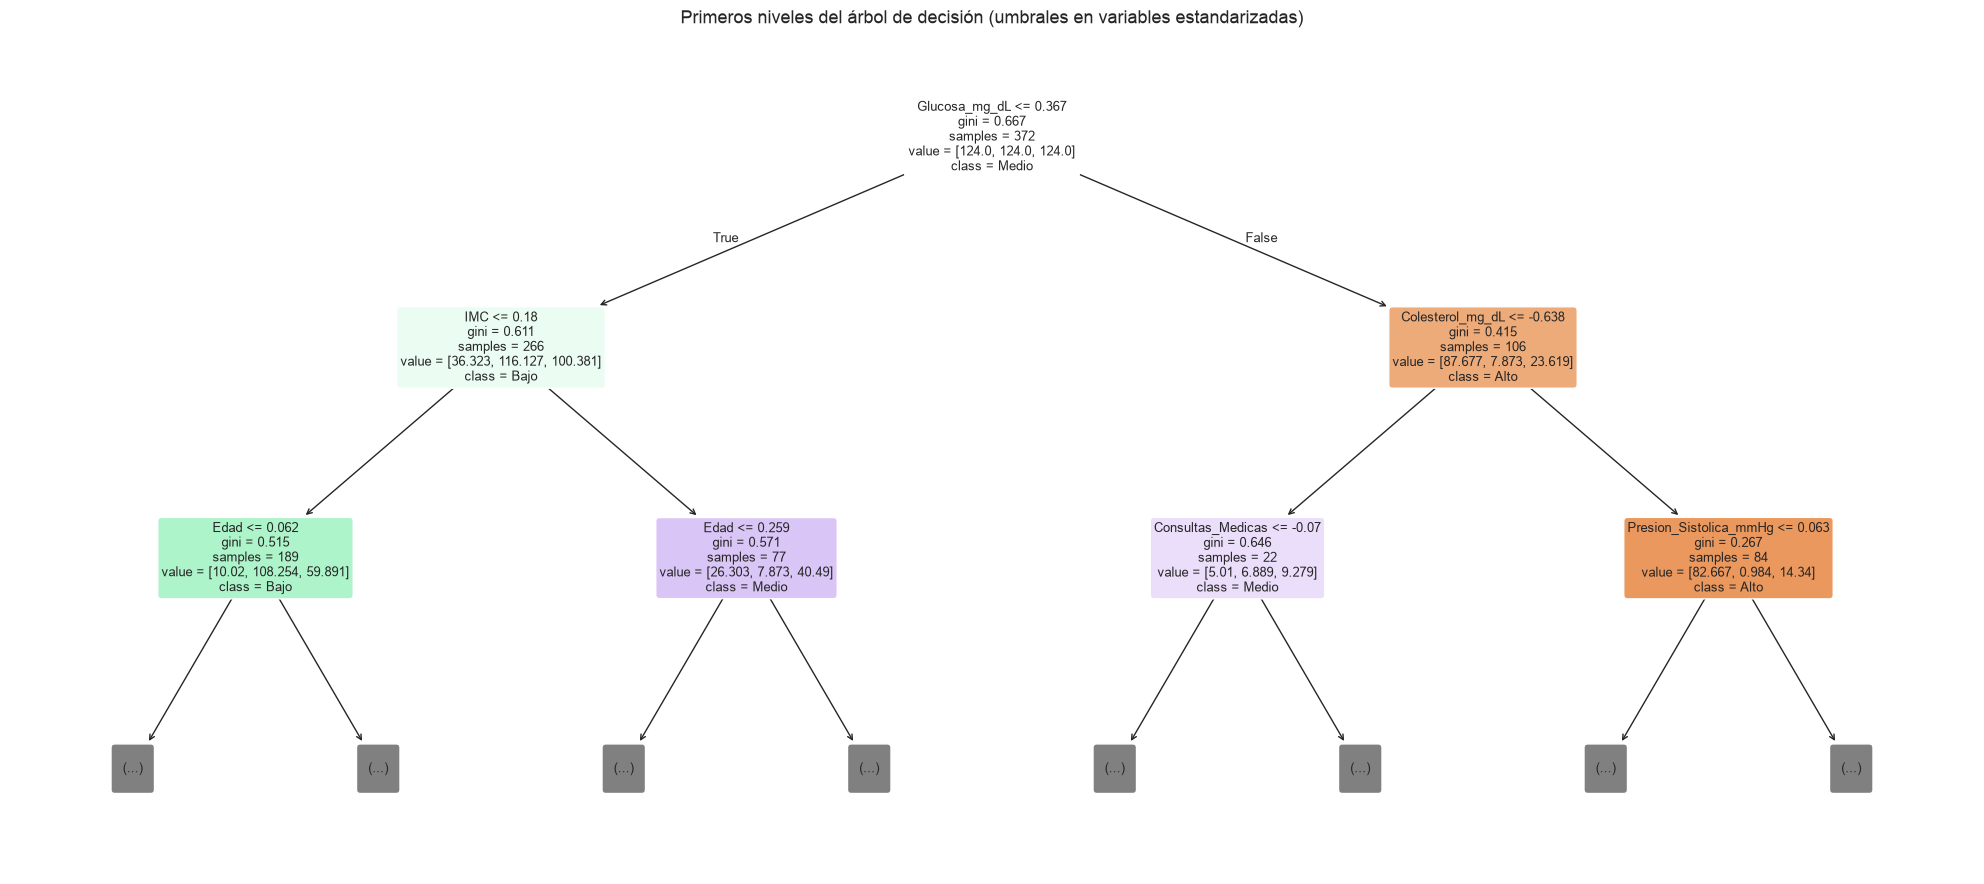

In [28]:
arbol = pipelines["Árbol de decisión"]
nombres = [n.split("__")[1] for n in arbol.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(20, 9))
plot_tree(arbol.named_steps["modelo"], feature_names=nombres, class_names=list(arbol.named_steps["modelo"].classes_),
          filled=True, rounded=True, max_depth=2, fontsize=9)
plt.title("Primeros niveles del árbol de decisión (umbrales en variables estandarizadas)")
plt.tight_layout()
plt.show()


**Interpretación (Figura 10 y tabla de importancias).** En la regresión logística, la probabilidad de la clase **Alto** aumenta sobre todo con la **glucosa** (coeficiente 2.435 por desviación estándar), la **actividad física baja** (1.644), la **presión sistólica** (1.479), la **edad** (1.464), el **IMC** (1.174) y ser **fumador** (1.078). La **actividad física alta** (−1.392) y más **horas de sueño** (−0.855) se asocian con menor probabilidad de Alto. `Consultas_Medicas` casi no aporta (0.099).

En el random forest, las variables más importantes son glucosa (0.213), edad (0.181), IMC (0.167) y presión (0.123), y el árbol individual coincide en glucosa, edad e IMC como primeras divisiones. Que tres modelos distintos coincidan en las variables principales da solidez a la interpretación. Aun así, **importancia no implica causalidad**: la etiqueta se construyó a partir de estas variables, de modo que los modelos están recuperando esa regla de construcción. Además, en presencia de variables correlacionadas (edad, presión y colesterol), la importancia se reparte de forma inestable.

# 5. Conclusiones del notebook

**¿Cuáles fueron los principales hallazgos del EDA?**
El dataset final tiene 497 registros (3 duplicados retirados), pocos nulos (≤ 1.4 % por variable) y valores extremos plausibles que se conservaron. La variable objetivo tiene un desbalance leve (39.4 % Medio, 34.0 % Bajo, 26.6 % Alto). Edad, IMC, presión, colesterol y glucosa aumentan de forma ordenada de Bajo a Alto (diferencias estandarizadas Alto–Bajo de 1.21 a 1.81 DE), y la actividad física baja y el tabaquismo se asocian con mayor proporción de riesgo Alto. Sueño y estrés casi no diferencian las clases, y no existe multicolinealidad fuerte (|r| ≤ 0.47).

**¿Qué modelo produjo los resultados más adecuados?**
La **regresión logística multinomial** con pesos balanceados.

**¿Qué evidencias respaldan esa selección?**
Obtuvo el mejor F1-macro en prueba (0.856) y en validación cruzada (0.844 ± 0.030), la menor brecha entre entrenamiento y prueba (0.015), un recall de Alto de 0.848 (igual al del random forest) y ningún error Bajo ↔ Alto. Todos sus errores fueron entre clases vecinas. Además, sus coeficientes son interpretables.

**¿Qué errores o limitaciones se identificaron?**
(1) Cinco pacientes Alto se clasificaron como Medio y la clase Medio es la más difícil (F1 de 0.812), porque comparte rasgos con ambas clases vecinas. (2) El random forest sobreajusta (F1 de entrenamiento 0.985) y el árbol rinde poco con la profundidad fijada. (3) Los datos son **sintéticos** y la etiqueta se construyó a partir de las mismas variables, por lo que el desempeño mide la recuperación de una regla didáctica y no se puede trasladar a la práctica clínica. (4) El tamaño de muestra es moderado (497) y el grupo `Otro/No reporta` tiene solo 12 personas. (5) No se ajustaron hiperparámetros ni el umbral de decisión.

**Pendiente para el tercer corte:** ajustar hiperparámetros con validación cruzada, explorar umbrales que prioricen el recall de Alto, evaluar un modelo ordinal que aproveche el orden Bajo < Medio < Alto y analizar la estabilidad de los coeficientes.

# 6. Tercer corte: revisión, optimización y exportación del modelo

## 6.1 Revisión del rendimiento del segundo corte

Antes de integrar el modelo en Streamlit se revisaron las métricas de la sección 4 con la *Ficha técnica de revisión de calidad del modelado*:

| Aspecto revisado | Resultado | ¿Requiere acción? |
|---|---|---|
| Accuracy / F1-macro (prueba) | 0.856 / 0.856 con la regresión logística | No: supera la alerta del 70 % |
| Recall por clase | Bajo 0.930 · Medio 0.796 · **Alto 0.848** | Vigilar: 5 pacientes Alto quedaron como Medio |
| Validación cruzada (5 particiones) | F1-macro 0.844 ± 0.030 | No: es estable |
| Sobreajuste | Brecha train–test de 0.015 | No |
| Fuga de información | Duplicados retirados antes de dividir; imputación, escalamiento y codificación dentro del `Pipeline` | No |
| Desbalance | Razón 1.48; estratificación y `class_weight="balanced"` | No |
| Colinealidad | \|r\| ≤ 0.47 | No |
| Hiperparámetros | **No se habían ajustado** (C = 1 por defecto) | **Sí** → sección 6.2 |

El modelo no está por debajo del 70 %, así que no hay un problema del pipeline que corregir. El punto pendiente que dejó el segundo corte es el **ajuste de hiperparámetros**. Se ajusta la regularización `C` de la regresión logística con validación cruzada **solo sobre el conjunto de entrenamiento**, para que el conjunto de prueba siga siendo una evaluación independiente.

## 6.2 Optimización de hiperparámetros con validación cruzada (solo entrenamiento)

In [29]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

pipeline_base = pipelines["Regresión logística"]          # modelo seleccionado en el segundo corte (C = 1)

rejilla = {
    "modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    "modelo__class_weight": [None, "balanced"],
}
cv_interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busqueda = GridSearchCV(
    clone(pipeline_base), rejilla, scoring="f1_macro", cv=cv_interna, n_jobs=-1, return_train_score=True
)
busqueda.fit(X_train, y_train)

resultados_busqueda = (
    pd.DataFrame(busqueda.cv_results_)
    .assign(C=lambda d: d["param_modelo__C"], pesos=lambda d: d["param_modelo__class_weight"].astype(str))
    [["C", "pesos", "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]]
    .sort_values("rank_test_score")
)
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"F1-macro CV (entrenamiento) del mejor: {busqueda.best_score_:.3f}")
resultados_busqueda.head(8).round(3)

Mejores hiperparámetros: {'modelo__C': 0.3, 'modelo__class_weight': 'balanced'}
F1-macro CV (entrenamiento) del mejor: 0.843


,C,pesos,mean_test_score,std_test_score,mean_train_score,rank_test_score
7,0.3,balanced,0.843,0.032,0.869,1
6,0.3,NaN,0.842,0.043,0.870,2
13,10.0,balanced,0.836,0.043,0.889,3
9,1.0,balanced,0.835,0.040,0.879,4
15,30.0,balanced,0.834,0.045,0.887,5
8,1.0,NaN,0.833,0.036,0.876,6
12,10.0,NaN,0.831,0.031,0.880,7
14,30.0,NaN,0.831,0.036,0.881,8


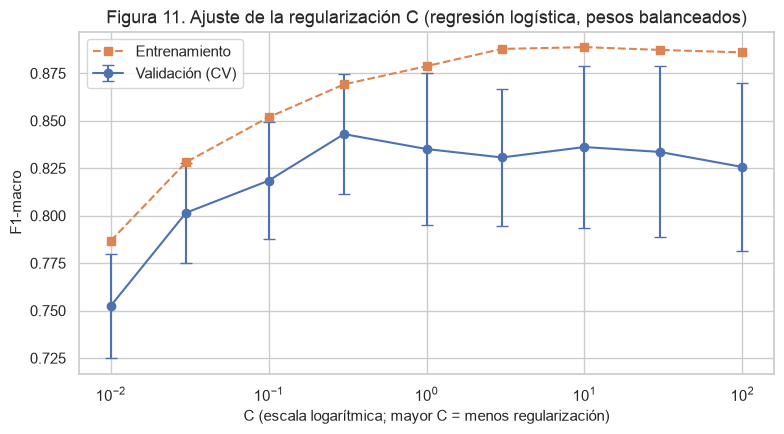

In [30]:
# Curva de validación: F1-macro en función de C (pesos balanceados)
curva = resultados_busqueda[resultados_busqueda["pesos"] == "balanced"].sort_values("C")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(curva["C"], curva["mean_test_score"], yerr=curva["std_test_score"], marker="o", capsize=4,
            label="Validación (CV)")
ax.plot(curva["C"], curva["mean_train_score"], marker="s", linestyle="--", label="Entrenamiento")
ax.set_xscale("log")
ax.set(title="Figura 11. Ajuste de la regularización C (regresión logística, pesos balanceados)",
       xlabel="C (escala logarítmica; mayor C = menos regularización)", ylabel="F1-macro")
ax.legend()
plt.tight_layout()
guardar("fig11_ajuste_C")
plt.show()

## 6.3 Comparación antes y después de la optimización

In [31]:
pipeline_optimizado = busqueda.best_estimator_          # ya reentrenado con todo X_train
candidatos = {"Antes (C = 1, segundo corte)": pipeline_base, "Después (optimizado)": pipeline_optimizado}

filas = []
for nombre, pipe in candidatos.items():
    pred = pipe.predict(X_test)
    cv_res = cross_validate(clone(pipe), X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    filas.append({
        "Versión": nombre,
        **metricas(y_test, pred),
        "Accuracy_train": accuracy_score(y_train, pipe.predict(X_train)),
        "Accuracy_CV": cv_res["test_accuracy"].mean(),
        "F1_macro_CV": cv_res["test_f1_macro"].mean(),
        "F1_macro_CV_desv": cv_res["test_f1_macro"].std(),
        "Alto_no_detectados": int(((y_test == "Alto") & (pred != "Alto")).sum()),
    })
antes_despues = pd.DataFrame(filas).set_index("Versión")
antes_despues.T.round(3)

Versión,"Antes (C = 1, segundo corte)",Después (optimizado)
Accuracy,0.856,0.816
Precision_macro,0.854,0.818
Recall_macro,0.858,0.821
F1_macro,0.856,0.820
Recall_Alto,0.848,0.848
Accuracy_train,0.871,0.871
Accuracy_CV,0.841,0.831
F1_macro_CV,0.844,0.835
F1_macro_CV_desv,0.030,0.042
Alto_no_detectados,5.000,5.000


In [32]:
# Regla de decisión fijada ANTES de ver el conjunto de prueba:
# se adopta la versión optimizada solo si mejora el F1-macro de la validación cruzada (criterio principal)
# sin empeorar el recall de la clase Alto en prueba (error más costoso).
mejora_cv = antes_despues.loc["Después (optimizado)", "F1_macro_CV"] - antes_despues.loc["Antes (C = 1, segundo corte)", "F1_macro_CV"]
recall_alto_ok = (antes_despues.loc["Después (optimizado)", "Recall_Alto"]
                  >= antes_despues.loc["Antes (C = 1, segundo corte)", "Recall_Alto"])

if mejora_cv > 0 and recall_alto_ok:
    version_final, pipeline_final = "Después (optimizado)", pipeline_optimizado
else:
    version_final, pipeline_final = "Antes (C = 1, segundo corte)", pipeline_base

print(f"Cambio en F1-macro CV: {mejora_cv:+.4f} | ¿Recall de Alto se mantiene o mejora?: {recall_alto_ok}")
print("Versión seleccionada para la aplicación:", version_final)
print("Hiperparámetros finales:", {k: v for k, v in pipeline_final.named_steps["modelo"].get_params().items()
                                   if k in ("C", "class_weight", "max_iter")})

Cambio en F1-macro CV: -0.0093 | ¿Recall de Alto se mantiene o mejora?: True
Versión seleccionada para la aplicación: Antes (C = 1, segundo corte)
Hiperparámetros finales: {'C': 1.0, 'class_weight': 'balanced', 'max_iter': 2000}


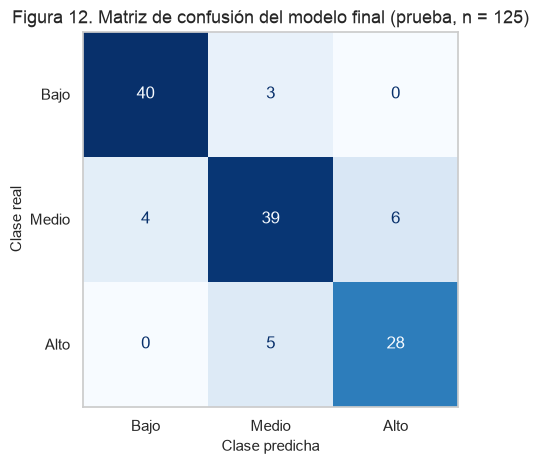

,precision,recall,f1-score,support
Bajo,0.909,0.930,0.920,43.0
Medio,0.830,0.796,0.812,49.0
Alto,0.824,0.848,0.836,33.0


In [33]:
pred_final = pipeline_final.predict(X_test)
matriz_final = confusion_matrix(y_test, pred_final, labels=ORDEN_RIESGO)

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay(matriz_final, display_labels=ORDEN_RIESGO).plot(ax=ax, cmap="Blues", values_format="d",
                                                                       colorbar=False)
ax.set(title="Figura 12. Matriz de confusión del modelo final (prueba, n = 125)",
       xlabel="Clase predicha", ylabel="Clase real")
ax.grid(False)
plt.tight_layout()
guardar("fig12_matriz_final")
plt.show()

reporte_final = pd.DataFrame(
    classification_report(y_test, pred_final, labels=ORDEN_RIESGO, output_dict=True, zero_division=0)
).T.loc[ORDEN_RIESGO, ["precision", "recall", "f1-score", "support"]]
reporte_final.round(3)

**Interpretación (sección 6.3).**

- La búsqueda en rejilla (9 valores de `C` × con o sin pesos balanceados) se hizo **solo con el conjunto de entrenamiento**, con validación cruzada interna de 5 particiones. La mejor combinación fue `C = 0.3` con pesos balanceados (F1-macro CV interno 0.843). La diferencia frente a `C = 1` (0.835) es menor que la desviación estándar entre particiones (≈ 0.03 a 0.04), así que la curva de la Figura 11 es prácticamente plana entre `C = 0.3` y `C = 30`: la regularización no es un factor crítico en este problema.
- Al evaluar la versión optimizada con la misma validación cruzada de 5 particiones sobre los 497 registros, **no mejoró**: F1-macro CV de 0.835 ± 0.042 frente a 0.844 ± 0.030 del modelo original. En prueba bajó de 0.856 a 0.820. El recall de **Alto** es igual en ambas (0.848; 5 pacientes Alto no detectados).
- Aplicando la regla fijada de antemano (mejorar el F1-macro de CV sin empeorar el recall de Alto), **se conserva el modelo del segundo corte**: regresión logística multinomial con `C = 1` y `class_weight="balanced"`. La mejora aparente en la CV interna era ruido de las particiones, y la evaluación posterior lo confirmó. Este resultado también descarta el sobreajuste del modelo original.
- El modelo final tiene accuracy de 0.856, F1-macro de 0.856 en prueba y F1-macro CV de 0.844 ± 0.030, todos muy por encima de la alerta del 70 %. Las 18 equivocaciones son entre clases vecinas, sin ninguna confusión Bajo ↔ Alto (Figura 12). Como la clase Medio sigue siendo la más difícil (recall 0.796), la aplicación muestra siempre las **probabilidades de las tres clases** y no solo la etiqueta.


## 6.4 Exportación del pipeline completo para Streamlit

Se guarda con `joblib` el **pipeline completo** (imputación, escalamiento, one-hot y regresión logística). La aplicación carga este archivo y **no vuelve a entrenar** el modelo. Junto al pipeline se guardan:

- `modelo/metadatos.json`: variables, categorías válidas, rangos observados, métricas finales, matriz de confusión, resultados de validación cruzada y versiones de las librerías.
- `modelo/conjunto_prueba.csv`: los 125 registros de prueba con la clase real, la predicción y las probabilidades del notebook, para verificar que la app produce exactamente lo mismo.

In [34]:
import json
import platform

import joblib
import sklearn

CARPETA_MODELO = Path("modelo")
CARPETA_MODELO.mkdir(exist_ok=True)

joblib.dump(pipeline_final, CARPETA_MODELO / "pipeline_riesgo.joblib", compress=3)

# Conjunto de prueba con predicciones y probabilidades del notebook
proba_final = pipeline_final.predict_proba(X_test)
clases = list(pipeline_final.classes_)
prueba = df.loc[X_test.index, ["ID_Paciente"] + variables_predictoras].copy()
prueba["Nivel_Riesgo_real"] = y_test.values
prueba["Prediccion_notebook"] = pred_final
for i, c in enumerate(clases):
    prueba[f"Prob_{c}"] = proba_final[:, i].round(6)
prueba.to_csv(CARPETA_MODELO / "conjunto_prueba.csv", index=False)

cv_final = cross_validate(clone(pipeline_final), X, y, cv=cv, scoring=["accuracy", "f1_macro"])
fila_final = antes_despues.loc[version_final]
metadatos = {
    "modelo": "Regresión logística multinomial",
    "version_seleccionada": version_final,
    "hiperparametros": {"C": float(pipeline_final.named_steps["modelo"].C),
                        "class_weight": pipeline_final.named_steps["modelo"].class_weight},
    "semilla": SEMILLA,
    "variables_numericas": variables_numericas,
    "variables_categoricas": variables_categoricas,
    "categorias": {c: sorted(df[c].dropna().unique().tolist()) for c in variables_categoricas},
    "rangos_observados": {c: [float(df[c].min()), float(df[c].max())] for c in variables_numericas},
    "medianas": {c: float(df[c].median()) for c in variables_numericas},
    "clases": ORDEN_RIESGO,
    "n_entrenamiento": int(len(X_train)),
    "n_prueba": int(len(X_test)),
    "metricas_prueba": {
        "accuracy": accuracy_score(y_test, pred_final),
        "precision_macro": precision_score(y_test, pred_final, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, pred_final, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, pred_final, average="macro", zero_division=0),
        "accuracy_entrenamiento": accuracy_score(y_train, pipeline_final.predict(X_train)),
    },
    "metricas_por_clase": {c: {k: float(reporte_final.loc[c, k]) for k in ["precision", "recall", "f1-score", "support"]}
                           for c in ORDEN_RIESGO},
    "validacion_cruzada": {
        "accuracy_media": float(cv_final["test_accuracy"].mean()),
        "f1_macro_media": float(cv_final["test_f1_macro"].mean()),
        "f1_macro_desv": float(cv_final["test_f1_macro"].std()),
        "f1_macro_particiones": [float(v) for v in cv_final["test_f1_macro"]],
    },
    "matriz_confusion": matriz_final.tolist(),
    "antes_despues": antes_despues.reset_index().round(4).to_dict(orient="records"),
    "comparacion_modelos_corte2": comparacion.reset_index().round(4).to_dict(orient="records"),
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
(CARPETA_MODELO / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

for archivo in sorted(CARPETA_MODELO.iterdir()):
    print(f"{archivo}  ({archivo.stat().st_size / 1024:.1f} KB)")

modelo/conjunto_prueba.csv  (12.0 KB)
modelo/metadatos.json  (4.1 KB)
modelo/pipeline_riesgo.joblib  (2.5 KB)


## 6.5 Verificación: el archivo exportado reproduce las predicciones del notebook

In [35]:
pipeline_cargado = joblib.load(CARPETA_MODELO / "pipeline_riesgo.joblib")

assert (pipeline_cargado.predict(X_test) == pred_final).all()
assert np.allclose(pipeline_cargado.predict_proba(X_test), proba_final)
print("OK: el pipeline cargado desde disco produce las mismas predicciones y probabilidades en los 125 registros de prueba.")

# Registros de referencia para comprobar en la aplicación (pestaña Predicción → 'Cargar un registro del conjunto de prueba')
ejemplos = prueba.set_index("ID_Paciente").loc[
    lambda d: d.groupby("Nivel_Riesgo_real").head(1).index.union(d[d["Nivel_Riesgo_real"] != d["Prediccion_notebook"]].head(1).index)
]
ejemplos[["Nivel_Riesgo_real", "Prediccion_notebook"] + [f"Prob_{c}" for c in clases]].round(3)

OK: el pipeline cargado desde disco produce las mismas predicciones y probabilidades en los 125 registros de prueba.


,Nivel_Riesgo_real,Prediccion_notebook,Prob_Alto,Prob_Bajo,Prob_Medio
ID_Paciente,,,,,
PAC-0066,Medio,Alto,0.906,0.001,0.093
PAC-0086,Alto,Alto,0.998,0.000,0.002
PAC-0315,Medio,Medio,0.134,0.012,0.854
PAC-0496,Bajo,Bajo,0.002,0.515,0.482


In [36]:
# Caso normal y caso inválido usados en las pruebas de la aplicación
caso_normal = pd.DataFrame([{
    "Edad": 45, "IMC": 26.5, "Glucosa_mg_dL": 100, "Presion_Sistolica_mmHg": 120, "Colesterol_mg_dL": 190,
    "Horas_Sueno": 7.0, "Nivel_Estres": 5, "Consultas_Medicas": 2,
    "Genero": "Femenino", "Actividad_Fisica": "Moderada", "Fumador": "No",
}])
print("Caso normal →", pipeline_cargado.predict(caso_normal)[0],
      dict(zip(clases, pipeline_cargado.predict_proba(caso_normal)[0].round(3))))

Caso normal → Bajo {'Alto': np.float64(0.003), 'Bajo': np.float64(0.505), 'Medio': np.float64(0.492)}


## 6.6 Conclusiones del tercer corte

1. **Revisión:** el modelo del segundo corte no presentaba alertas: métricas superiores a 0.70, sin fuga de información, sin sobreajuste (brecha de 0.015) y con validación cruzada estable (0.844 ± 0.030). El único pendiente era ajustar los hiperparámetros.
2. **Optimización:** se ajustaron `C` y los pesos de clase con validación cruzada sobre el entrenamiento. La mejor combinación (`C = 0.3`) **no superó** al modelo original en la validación cruzada completa (0.835 frente a 0.844) ni en prueba, así que se conservó la regresión logística con `C = 1` y pesos balanceados. La elección se basó en el F1-macro y en el recall de Alto, no solo en el accuracy.
3. **Despliegue:** el pipeline completo (imputación, escalamiento, one-hot y modelo) se guardó con `joblib`. La aplicación de Streamlit (`app.py`) lo carga sin reentrenar. La sección 6.5 comprueba con `assert` que el archivo exportado reproduce exactamente las predicciones y probabilidades del notebook en los 125 registros de prueba. Con `conjunto_prueba.csv` se puede verificar lo mismo registro a registro desde la app (por ejemplo, `PAC-0086`: Alto, P(Alto) = 0.998).
4. **Limitaciones que se mantienen:** los datos son sintéticos, con una etiqueta didáctica construida a partir de las mismas variables. La muestra es moderada (497 registros), el grupo `Otro/No reporta` es muy pequeño y persisten las confusiones entre clases vecinas, sobre todo con Medio. La aplicación es un **prototipo académico** y no sustituye una valoración médica profesional.
